# Assignment 3 — Sampling Distributions and Estimation

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — Sampling distributions and the CLT](#part1)
2. [Part 2 — Estimating mean sensor error](#part2)
3. [Part 3 — Estimating a false-rejection proportion](#part3)
4. [Part 4 — AI-use and conclusion](#part4)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, norm, probplot

DATA = "data/"

sensors = pd.read_csv(DATA + "assignment03_sensor_calibration.csv")   # Part 2

print(f"sensors: {sensors.shape[0]} rows x {sensors.shape[1]} columns")

sensors: 64 rows x 2 columns


<a id="part2"></a>
# Part 2 — Estimating mean sensor error

> The file `assignment03_sensor_calibration.csv` contains calibration errors from 64 independently
> selected temperature sensors. Error is `sensor reading - reference temperature`. Let $\mu$ be the
> population mean calibration error.

Let $X$ be one sensor's calibration error. $X_1, \dots, X_n$ are the $n=64$ independently selected
sensors in this sample, and $\bar X$ and $S$ are the usual estimators of $\mu$ and $\sigma$:
$\bar X \to \mu$, $S \to \sigma$.

## a)

> Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus
> standard error.

$$\bar x = \frac{1}{n}\sum_{i=1}^n x_i, \qquad s = \sqrt{\frac{1}{n-1}\sum_{i=1}^n (x_i-\bar x)^2}, \qquad \text{SE} = \frac{s}{\sqrt n}$$

In [2]:
error = sensors["calibration_error_c"]

n = len(error)
xbar = error.mean()
s = error.std(ddof=1)
se = s / np.sqrt(n)

print(f"n    = {n}")
print(f"xbar = {xbar:.4f} C")
print(f"s    = {s:.4f} C")
print(f"SE   = {se:.4f} C")

n    = 64
xbar = 0.1883 C
s    = 0.6257 C
SE   = 0.0782 C


**SD versus SE:** $s$ describes the spread of individual calibration errors across the 64 sensors
sampled. SE describes the spread of $\bar X$ across repeated samples of size $n=64$, and is always
smaller because averaging cancels out some of the individual variation: SE $= s/\sqrt n = 0.6257/\sqrt{64} = 0.0782$ C, about an eighth of $s$.

## b)

> Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears
> reasonable and why plots cannot establish independence.

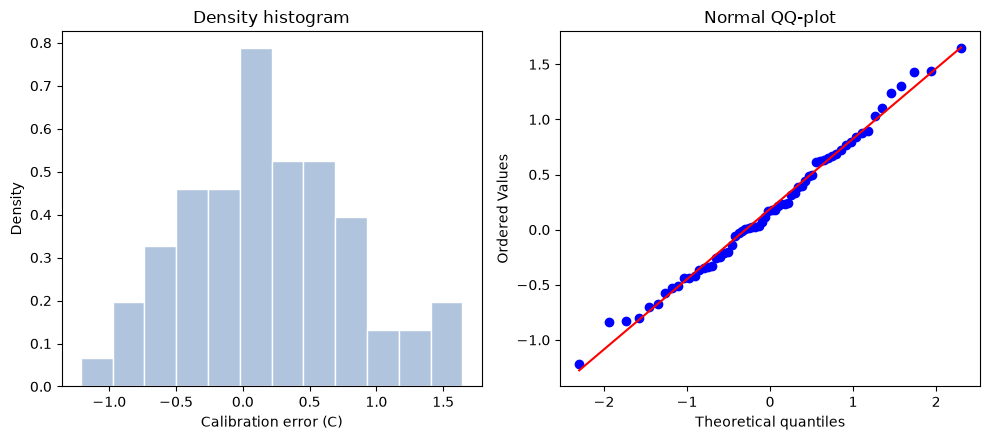

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

axes[0].hist(error, bins=12, density=True, color="lightsteelblue", edgecolor="white")
axes[0].set(xlabel="Calibration error (C)", ylabel="Density", title="Density histogram")

probplot(error, dist="norm", plot=axes[1])
axes[1].set_title("Normal QQ-plot")

plt.tight_layout()
plt.show()

**Shape:** the histogram is roughly symmetric and single-peaked, centred near 0.19 C, with no
1.5xIQR outliers. The QQ-plot points stay close to the line across the whole range, with only
mild, random-looking deviations at the ends.

**Is a $t$ interval reasonable:** yes. The $t$ interval only needs $\bar X$ to be approximately
normal, not the individual errors. With $n=64$ the CLT already helps, and the data show no strong
skew or heavy tails that would work against it.

**Why plots cannot establish independence:** a histogram and a QQ-plot only show the shape of the
64 values collected. They say nothing about how the sensors were selected or measured.
Independence is a property of the sampling design, whether one sensor's error has anything to do
with another's, not something visible in the values themselves. The assignment states the sensors
were "independently selected," which is a design assumption, not something the plots can confirm
or rule out.

## c)

> Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard
> error, and margin of error. Verify it with SciPy and interpret both the interval and the 95%
> confidence level correctly.

$$\bar X \pm t_{n-1,\,1-\alpha/2}\cdot\frac{s}{\sqrt n}, \qquad df = n-1$$

In [4]:
df = n - 1
alpha = 0.05
t_crit = t.ppf(1 - alpha / 2, df)
moe = t_crit * se
ci_lo, ci_hi = xbar - moe, xbar + moe

print(f"df      = {df}")
print(f"t*      = {t_crit:.4f}")
print(f"SE      = {se:.4f} C")
print(f"margin  = {t_crit:.4f} * {se:.4f} = {moe:.4f} C")
print(f"95% CI  = [{ci_lo:.4f}, {ci_hi:.4f}] C")

ci_scipy = t.interval(0.95, df, loc=xbar, scale=se)
print(f"SciPy   = [{ci_scipy[0]:.4f}, {ci_scipy[1]:.4f}] C")

df      = 63
t*      = 1.9983
SE      = 0.0782 C
margin  = 1.9983 * 0.0782 = 0.1563 C
95% CI  = [0.0320, 0.3446] C
SciPy   = [0.0320, 0.3446] C


**The interval:** the 95% $t$ interval is $[0.032,\ 0.345]$ C. Based on these 64 sensors,
population mean calibration errors between about 0.03 C and 0.34 C are plausible. The interval
lies entirely above 0, so the data suggest a small systematic positive bias, though the lower
bound is close to zero.

**What 95% means:** it describes the *procedure*, not this one interval. If the sampling were
repeated many times, each time with 64 new independently selected sensors, about 95% of the $t$
intervals built this way would contain the true $\mu$. For this particular interval, $\mu$ either
lies in $[0.032,\ 0.345]$ or it does not; we do not say $\mu$ lies in it with probability 0.95.

## d)

> Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence-precision
> trade-off.

In [5]:
rows = []
for confidence in (0.90, 0.95, 0.99):
    a = 1 - confidence
    tc = t.ppf(1 - a / 2, df)
    m = tc * se
    rows.append({"confidence": f"{confidence:.0%}", "t*": tc,
                 "lower": xbar - m, "upper": xbar + m, "width": 2 * m})

t_table = pd.DataFrame(rows).set_index("confidence")
t_table.round(4)

,t*,lower,upper,width
confidence,,,,
90%,1.6694,0.0577,0.3188,0.2612
95%,1.9983,0.0320,0.3446,0.3126
99%,2.6561,-0.0195,0.3960,0.4155


**Interpretation:** with the same 64 sensors, the width grows from about 0.26 C at 90% to 0.31 C
at 95% and 0.42 C at 99%. A higher confidence level needs a larger critical value $t^{*}$, so the
interval must be wider to capture $\mu$ in a larger share of repeated samples. This is the
confidence-precision trade-off: for a fixed $n$, more confidence costs precision. The only way to
get both is to collect more sensors, which shrinks the SE (see e).

## e)

> Using $s$ as a planning value and the normal critical value, find the smallest approximate
> sample size for a 95% margin of error no larger than $0.10\,^{\circ}\mathrm{C}$.

$$E = z^{*}\frac{s}{\sqrt n} \le 0.10 \quad\Rightarrow\quad n \ge \left(\frac{z^{*} s}{0.10}\right)^2, \qquad z^{*}=z_{0.975}\approx1.96$$

We use $s=0.6257$ C from the current sample as a planning value for $\sigma$, and the normal
critical value $z^{*}$ rather than $t^{*}$, because the degrees of freedom depend on the very
sample size we are trying to find.

In [6]:
z95 = norm.ppf(0.975)
target_moe = 0.10
n_exact = (z95 * s / target_moe) ** 2
n_required = int(np.ceil(n_exact))

print(f"z*           = {z95:.4f}")
print(f"n >=         = {n_exact:.2f}")
print(f"n required   = {n_required}")
for m in (n_required - 1, n_required):
    print(f"n = {m}: margin = {z95 * s / np.sqrt(m):.4f} C")

z*           = 1.9600
n >=         = 150.42
n required   = 151
n = 150: margin = 0.1001 C
n = 151: margin = 0.0998 C


**Result:** $n=151$ sensors. At $n=150$ the margin is just above the 0.10 C target; at $n=151$ it
drops just below. We always round up, since rounding down would miss the target. This is about
2.4 times the current sample of 64, the cost of roughly halving the margin from about 0.16 C
(part c) to 0.10 C.

## f)

> With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval.
> Compare it with the $t$ interval and state what the comparison cannot validate.

**Percentile bootstrap.** Resample $n=64$ calibration errors with replacement from the observed
data, compute the resampled mean, repeat $B\ge10{,}000$ times, and take the 2.5th and 97.5th
percentiles of the $B$ resampled means as the 95% interval. Unlike the $t$ interval, this does not
assume $\bar X$ is normal, it builds the sampling distribution directly from the data.

In [7]:
rng = np.random.default_rng(2026)
B = 10_000
values = error.values
boot_means = np.empty(B)
for i in range(B):
    resample = rng.choice(values, size=n, replace=True)
    boot_means[i] = resample.mean()

boot_lo, boot_hi = np.percentile(boot_means, [2.5, 97.5])

print(f"bootstrap 95% CI = [{boot_lo:.4f}, {boot_hi:.4f}] C")
print(f"t        95% CI = [{ci_lo:.4f}, {ci_hi:.4f}] C")
print(f"bootstrap width  = {boot_hi - boot_lo:.4f} C")
print(f"t        width   = {ci_hi - ci_lo:.4f} C")

bootstrap 95% CI = [0.0408, 0.3413] C
t        95% CI = [0.0320, 0.3446] C
bootstrap width  = 0.3005 C
t        width   = 0.3126 C


**Comparison:** the bootstrap interval is close to the $t$ interval from (c), both centred near
0.19 C and of similar width. This agreement is expected: the data in (b) showed no strong skew or
heavy tails, so the normal-based $t$ interval and the resampling-based bootstrap interval tell a
similar story here.

**What the comparison cannot validate.** Both intervals are built from the same 64 observations,
so agreement between them only shows that the $t$ interval's normal approximation is adequate for
*this data's shape*. It says nothing about whether the sensors were actually independently
selected, or whether these 64 sensors represent the full population of sensors. Both methods
assume the sample itself is a valid random sample. If that assumption fails, for example if
several sensors came from the same faulty batch, both intervals would be wrong together;
closeness between them would not reveal it.